# Lecture 18b: Other SVD Applications

For a real matrix $A\in\mathbb R^{m\times n}$, write $A=U\Sigma V^T$ and set $p=\min(m,n)$. Full $U,V$ are orthogonal and full $\Sigma$ is $m\times n$. The reduced factors have shapes $m\times p$, $p\times p$, and $p\times n$ in product order. Throughout, $\sigma_1\ge\cdots\ge\sigma_p\ge0$; if factors are provided in a different order, move each singular value together with its two singular vectors.

## 1. Rank, Range, and Null Space

Multiplying by columns of $U$ and rows of $V^T$ writes
$$A=\sum_{i=1}^{p}\sigma_i u_i v_i^T.$$
Every nonzero term has rank one. Since multiplication by invertible matrices preserves rank, $r=\operatorname{rank}(A)=\operatorname{rank}(\Sigma)$ is the number of positive singular values. Equivalently, $Av_i=\sigma_i u_i$ and the $u_i$ form an orthonormal basis.
$$\operatorname{range}(A)=\operatorname{span}(u_1,\ldots,u_r),\qquad
\ker(A)=\operatorname{span}(v_{r+1},\ldots,v_n).$$
Use full $V$ to recover all $n-r$ null directions: for $n>m$, some directions are omitted from reduced $V_R$. Full rank means $r=p$, so a wide full rank matrix may still have a nontrivial right null space. A square singular matrix has at least one zero singular value, but still has a full SVD with orthogonal factors.

In floating point arithmetic, a zero singular value can appear as a tiny nonzero one. The effective rank counts values above a tolerance; one common default is $\tau=\sigma_1\max(m,n)\epsilon$, where $\epsilon$ is machine precision. Measurement noise may justify a larger tolerance.

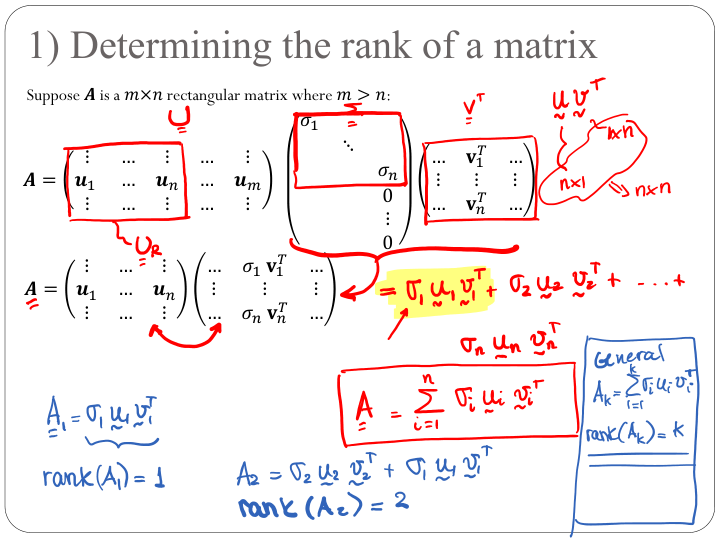

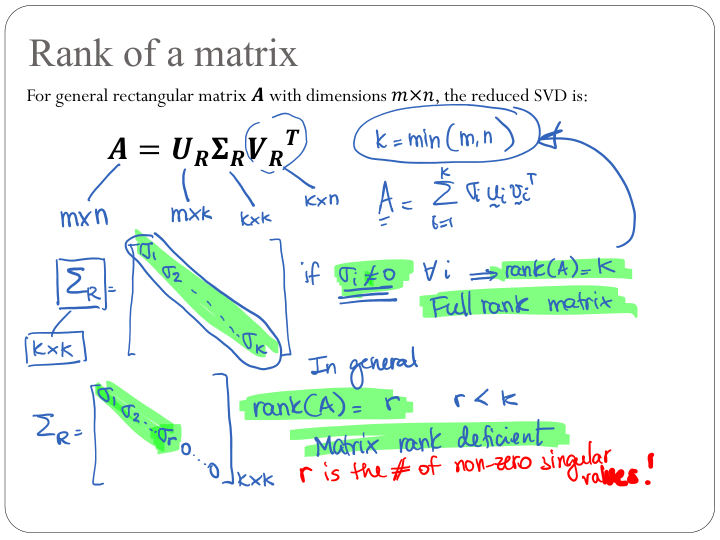

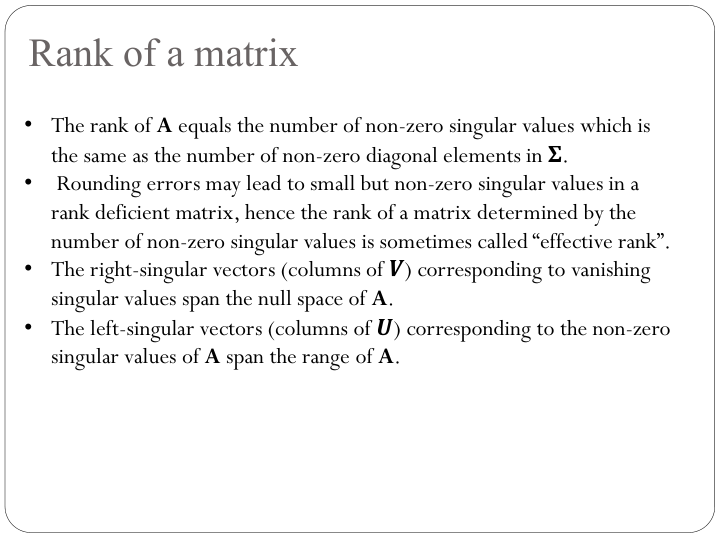

<details>
<summary>Example: Full row rank does not imply an empty null space</summary>

A $2\times3$ matrix has singular values $8,4$. Give its reduced factor shapes, rank, and nullity.

<details>
<summary>Solution</summary>

$U_R$ and $\Sigma_R$ are $2\times2$; $V_R$ is $3\times2$. The rank is $2$, and the full $V$ has one extra column spanning $\ker(A)$.

</details>
</details>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[1., 2., 3.], [2., 4., 6.]])
U, s, Vt = np.linalg.svd(A, full_matrices=True)
tol = max(A.shape) * np.finfo(s.dtype).eps * s[0]
r = np.count_nonzero(s > tol)
range_basis = U[:, :r]
null_basis = Vt[r:, :].T
assert r == 1 and null_basis.shape == (3, 2)
assert np.allclose(A @ null_basis, 0)
assert np.allclose(range_basis @ range_basis.T @ A, A)
print('Singular values:', s, '| effective rank:', r)

Singular values: [8.36660027e+00 7.32018325e-16] | effective rank: 1


## 2. Moore–Penrose Pseudoinverse

When $A$ is rectangular or rank deficient, an ordinary two-sided inverse does not exist. In the full SVD, define $\Sigma^+\in\mathbb R^{n\times m}$ by reversing the shape and replacing each positive diagonal entry by its reciprocal, while leaving zero entries zero:
$$A^+=V\Sigma^+U^T=\sum_{i=1}^{r}\sigma_i^{-1}v_i u_i^T.$$
This specializes to $V\Sigma^{-1}U^T=A^{-1}$ for a nonsingular square matrix. For full column rank it also equals $(A^TA)^{-1}A^T$; that Gram matrix formula fails when columns are dependent. For full row rank the corresponding identity is $A^+=A^T(AA^T)^{-1}$.

The products $AA^+=U_rU_r^T$ and $A^+A=V_rV_r^T$ project onto the column and row spaces. They are symmetric, and $AA^+A=A$, $A^+AA^+=A^+$. These four properties characterize the Moore–Penrose inverse.

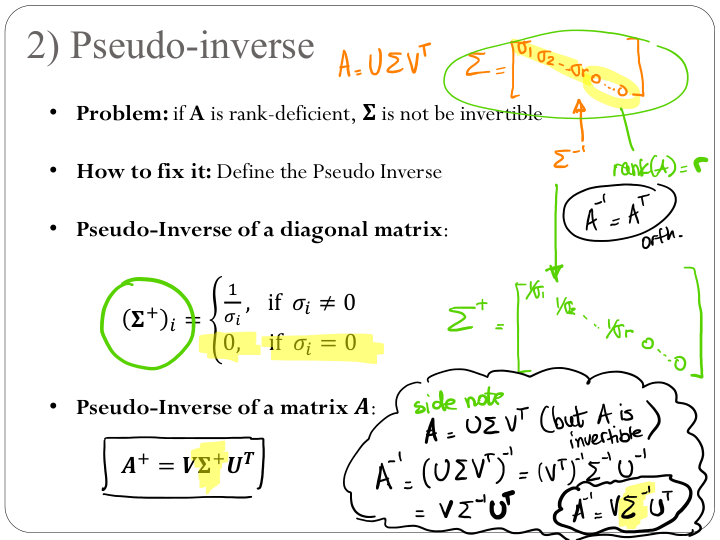

<details>
<summary>Example: Pseudoinverse of a rectangular diagonal matrix</summary>

Compute $A^+$ for $A=\begin{bmatrix}4&0&0\\0&0&0\end{bmatrix}$.

<details>
<summary>Solution</summary>

$A^+=\begin{bmatrix}1/4&0\\0&0\\0&0\end{bmatrix}$. The pseudoinverse is $3\times2$, and the zero singular value remains zero.

</details>
</details>

In [2]:
def svd_pseudoinverse(matrix):
    U, s, Vt = np.linalg.svd(matrix, full_matrices=False)
    tol = max(matrix.shape) * np.finfo(s.dtype).eps * s[0]
    keep = s > tol
    return (Vt[keep, :].T / s[keep]) @ U[:, keep].T

A_plus = svd_pseudoinverse(A)
assert np.allclose(A_plus, np.linalg.pinv(A))
assert np.allclose(A @ A_plus @ A, A)
assert np.allclose(A_plus @ A @ A_plus, A_plus)
assert np.allclose((A @ A_plus).T, A @ A_plus)
assert np.allclose((A_plus @ A).T, A_plus @ A)
print(A_plus)

[[0.01428571 0.02857143]
 [0.02857143 0.05714286]
 [0.04285714 0.08571429]]


## 3. Matrix 2-Norm

Recall that the induced 2-norm is $\|A\|_2=\max_{\|x\|_2=1}\|Ax\|_2$. For square orthogonal $Q$, $\|Qx\|_2^2=x^TQ^TQx=\|x\|_2^2$, so $\|Q\|_2=1$. With $y=V^Tx$,
$$\|Ax\|_2^2=\|\Sigma y\|_2^2
=\sum_{i=1}^{p}\sigma_i^2 y_i^2\le\sigma_1^2\|y\|_2^2.$$
Equality is attained at $x=v_1$, so $\|A\|_2=\sigma_1$. This is distinct from the Frobenius norm $\|A\|_F=(\sum_i\sigma_i^2)^{1/2}$.

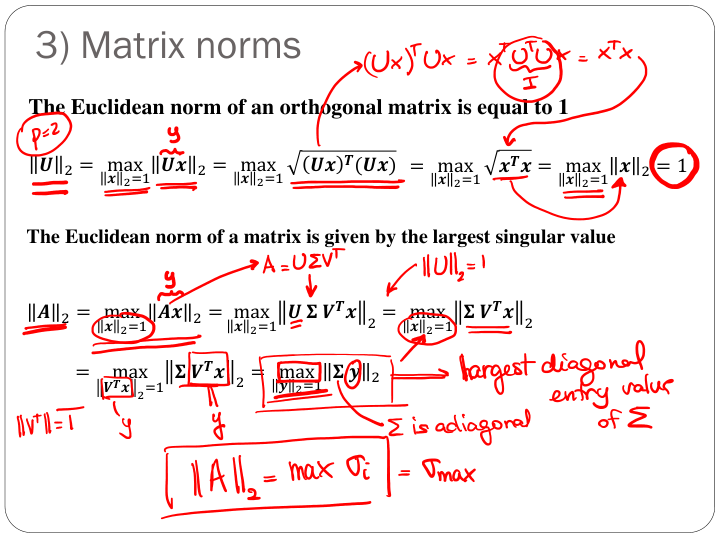

## 4. Inverse and Pseudoinverse Norms

When $A$ is square and nonsingular, the singular values of $A^{-1}$ are the reciprocals of the original values, in reverse order when sorted. Hence $\|A^{-1}\|_2=1/\sigma_p$. For a nonzero matrix of any shape, the largest singular value of $A^+$ is $1/\sigma_r$, the reciprocal of the smallest **positive** singular value. The zero matrix has zero pseudoinverse and zero pseudoinverse norm.

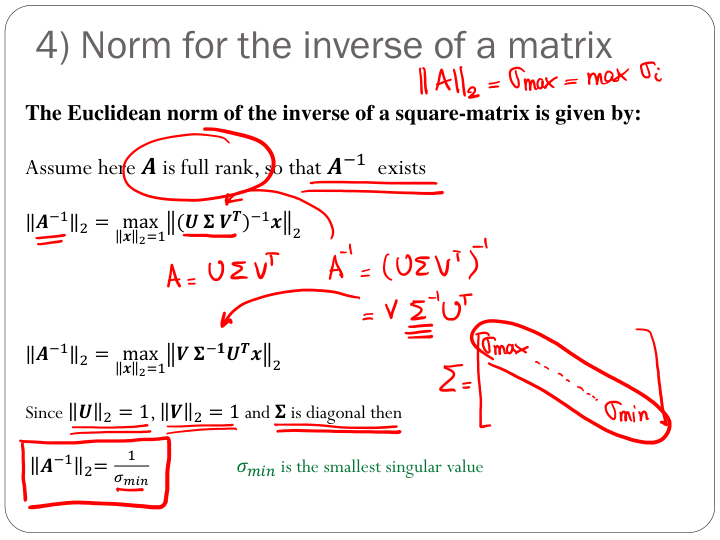

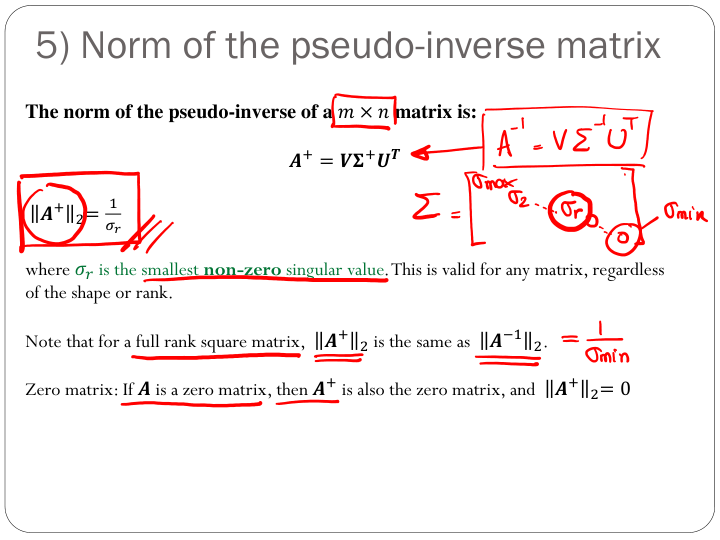

<details>
<summary>Example: Norm of a rank deficient pseudoinverse</summary>

The singular values are $0.05,0.25,0$. What are $\|A\|_2$ and $\|A^+\|_2$?

<details>
<summary>Solution</summary>

The largest original value gives $\|A\|_2=0.25$. The smallest positive value is $0.05$, so $\|A^+\|_2=20$.

</details>
</details>

## 5. Condition Number

The course uses
$$\operatorname{cond}_2(A)=
\begin{cases}
\sigma_1/\sigma_p,&r=p,\\
\infty,&r<p.
\end{cases}$$
For full rank this equals $\|A\|_2\|A^+\|_2$. For a nonzero rank deficient matrix, the product alone equals the finite ratio $\sigma_1/\sigma_r$, so the product is **not** a way to evaluate the course's rank deficient branch. A full row rank wide matrix has finite condition number under this convention, even though $Ax=b$ need not pick out a unique $x$. For a nonsingular square matrix, $\operatorname{cond}_2(A)$ bounds amplification of relative right-hand-side perturbations in a linear solve.

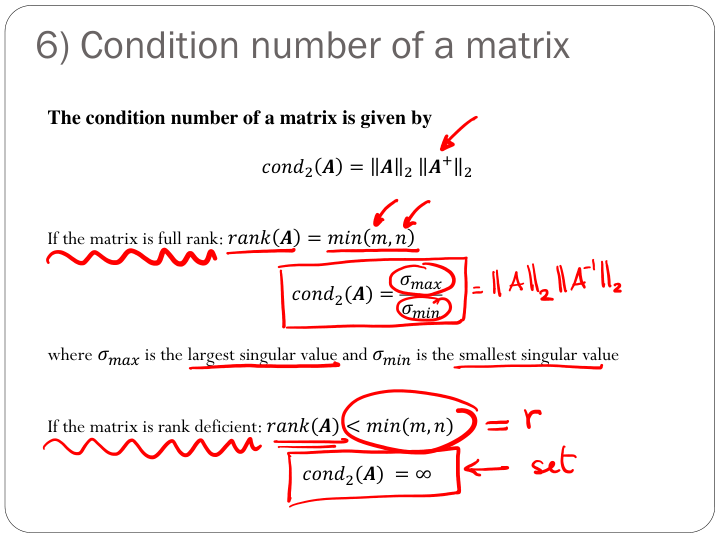

<details>
<summary>Example: Condition number from supplied SVD</summary>

The diagonal of $\Sigma$ is $(8,7,4)$. Find $\operatorname{cond}_2(A)$. What changes if the last entry becomes zero?

<details>
<summary>Solution</summary>

The original condition number is $8/4=2$. With diagonal $(8,7,0)$ the pseudoinverse norm is $1/7$, but the course condition number is infinite because the matrix is rank deficient.

</details>
</details>

## 6. Best Low-Rank Approximation

The truncated SVD keeps the $k$ largest singular triplets:
$$A_k=\sum_{i=1}^{k}\sigma_i u_i v_i^T=U_k\Sigma_k V_k^T.$$
Its rank is $\min(k,r)$. By the Eckart–Young–Mirsky theorem, $A_k$ minimizes the approximation error over all matrices of rank at most $k$ in both the induced 2-norm and the Frobenius norm:
$$\|A-A_k\|_2=\sigma_{k+1},\qquad
\|A-A_k\|_F=\left(\sum_{i>k}\sigma_i^2\right)^{1/2}.$$
If $k\ge r$, the error is zero, including $k=p$. The relative 2-norm error for nonzero $A$ is $\sigma_{k+1}/\sigma_1$ when $k<r$.

For the spectral norm lower bound, restrict any rank at most $k$ candidate $B$ to $\operatorname{span}(v_1,\ldots,v_{k+1})$. The restriction has a unit null vector $x$. Thus $\|(A-B)x\|_2=\|Ax\|_2\ge\sigma_{k+1}$. Truncation attains this bound because its residual keeps precisely the discarded triplets. For the Frobenius norm, the rank-one terms are orthogonal under the Frobenius inner product, which gives the displayed tail formula. A tie at the cutoff permits different optimal selections from the tied singular subspace.

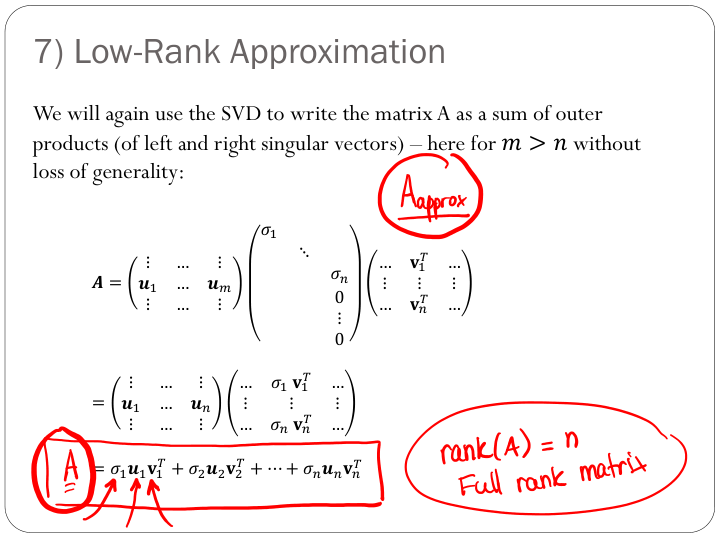

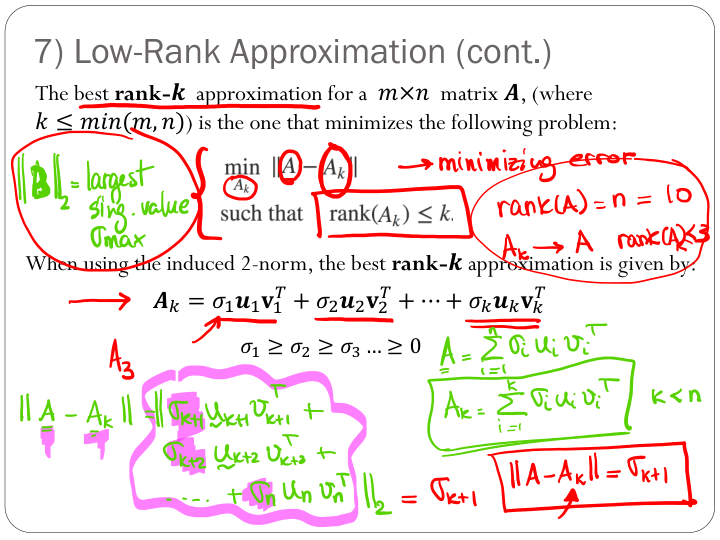

<details>
<summary>Example: Read the error from an eigendecomposition</summary>

If $A^TA$ has eigenvalues $6,5,2,0$, find the best rank-two error in the 2-norm.

<details>
<summary>Solution</summary>

The third singular value is $\sqrt2$, so the error is $\sqrt2$. The eigenvalue $2$ is the square of the error.

</details>
</details>

<details>
<summary>Example: Sort triplets before truncating</summary>

A supplied SVD has scaling entries $6,1.2,0.4,1.8$ in that order. Find the relative spectral error for rank two.

<details>
<summary>Solution</summary>

Keep the triplets for $6,1.8$. The first discarded value is $1.2$, so the relative error is $1.2/6=0.2$. Swapping corresponding columns of $U$, diagonal entries, and rows of $V^T$ preserves $A$.

</details>
</details>

<details>
<summary>Example: Detect zero approximation error without SVD</summary>

The second column of a nonzero $5\times2$ matrix is four times the first. What is the optimal rank-one spectral error?

<details>
<summary>Solution</summary>

The two columns span a one-dimensional space, so the matrix already has rank one. Taking $A_1=A$ gives zero error.

</details>
</details>

In [3]:
def truncate_svd(U, s, Vt, k):
    order = np.argsort(s)[::-1][:k]
    return (U[:, order] * s[order]) @ Vt[order, :]

M = np.diag([6., 1.2, .4, 1.8])
M2 = truncate_svd(np.eye(4), np.diag(M), np.eye(4), 2)
assert np.linalg.matrix_rank(M2) == 2
assert np.isclose(np.linalg.norm(M - M2, 2), 1.2)
assert np.isclose(np.linalg.norm(M - M2, 'fro'), np.hypot(1.2, .4))
print(M2)

[[6.  0.  0.  0. ]
 [0.  0.  0.  0. ]
 [0.  0.  0.  0. ]
 [0.  0.  0.  1.8]]


## 7. Image Compression and Storage

A grayscale image is an $m\times n$ array. A dense encoding stores $mn$ scalars; a rank $k$ factor encoding stores $k(m+n+1)$ scalars, including $k$ singular values. Reconstructing and saving the whole pixel array loses this storage advantage. With 64-bit scalars, the factor encoding saves $64[mn-k(m+n+1)]$ bits, ignoring headers and assuming the original pixels are also represented as 64-bit scalars.

The lecture illustrates a $500\times1417$ photograph at rank 50. The workspace uses grayscale versions of campus photos and compares different ranks. The runnable demonstration below uses an in-memory image so it has no file dependencies. In the course compression exercise, choose the first prefix whose sum of singular values **exceeds** $f\sum_i\sigma_i$; for an exact “at least” threshold use $\ge$ instead. This fraction measures retained singular-value sum, not retained Frobenius energy, which would use $\sum_i\sigma_i^2$. At $f=1$ a strict threshold has no solution; retain all components if the endpoint is allowed.

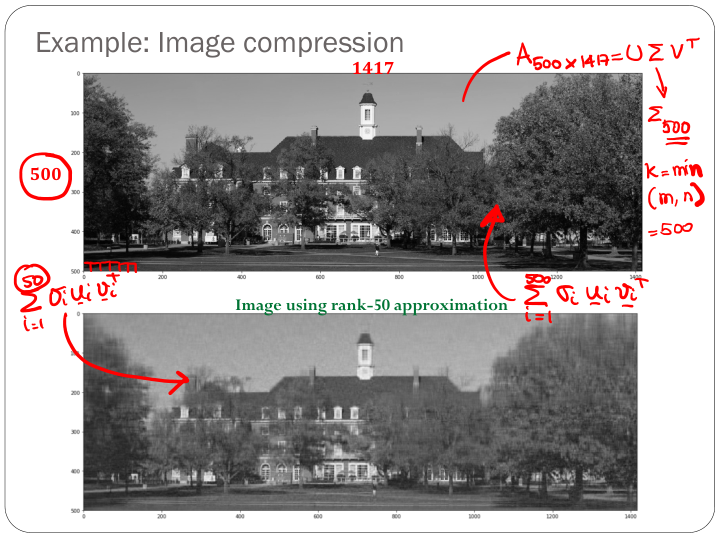

<details>
<summary>Example: Count the saved bits</summary>

For an $82\times24$ array of 64-bit numbers, find the savings at rank five.

<details>
<summary>Solution</summary>

The original stores $1968$ scalars, compared with $5(82+24+1)=535$ for the SVD factors. The savings are $(1968-535)\cdot64=91{,}712$ bits.

</details>
</details>

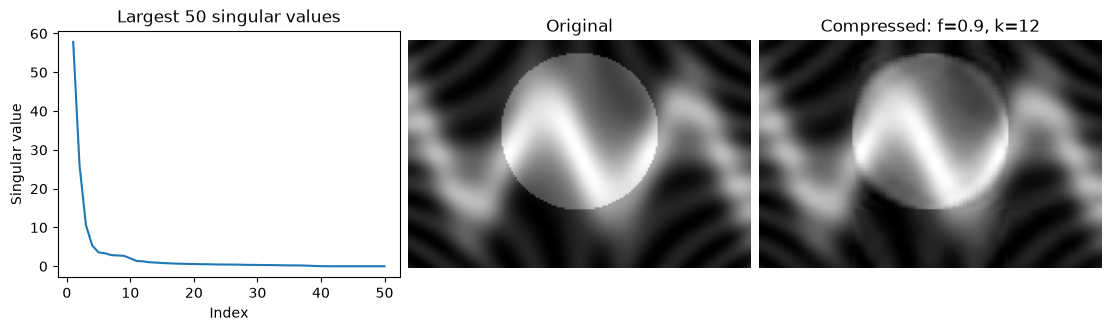

In [4]:
y, x = np.mgrid[-1:1:120j, -1.5:1.5:180j]
image = (0.7 * np.exp(-7 * (y - .4 * np.sin(5 * x))**2)
         + .3 * ((x*x + (y+.2)**2) < .48)
         + .08 * np.cos(16 * x*y))
Ui, si, Vti = np.linalg.svd(image, full_matrices=False)
f = .90
prefix = np.cumsum(si)
k = min(len(si), int(np.searchsorted(prefix, f * prefix[-1], side="right")) + 1)
image_compressed = (Ui[:, :k] * si[:k]) @ Vti[:k, :]
assert prefix[k-1] > f * prefix[-1]
assert k == 1 or prefix[k-2] <= f * prefix[-1]
assert np.allclose(image_compressed, truncate_svd(Ui, si, Vti, k))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), layout='constrained')
axes[0].plot(np.arange(1, 51), si[:50])
axes[0].set(xlabel='Index', ylabel='Singular value', title='Largest 50 singular values')
for ax, data, title in zip(axes[1:], (image, image_compressed),
                           ('Original', f'Compressed: f={f}, k={k}')):
    ax.imshow(data, cmap='gray', vmin=image.min(), vmax=image.max())
    ax.set_title(title)
    ax.axis('off')
plt.show()

## 8. Solve a Square Linear System

For square nonsingular $A=U\Sigma V^T$, solve $Ax=b$ without explicitly forming $A^{-1}$. First compute $z=U^Tb$, then $y_i=z_i/\sigma_i$, then $x=Vy$. Once the SVD is available, two dense matrix-vector products cost $O(n^2)$ and the elementwise division costs $O(n)$; the dense factorization itself is generally cubic.

For rank deficient or rectangular systems, replacing the division by zero with zero coefficients gives $x=A^+b$, the minimum Euclidean norm least-squares solution. If $b\notin\operatorname{range}(A)$ it does not solve $Ax=b$ exactly: $Ax=AA^+b$ is the orthogonal projection of $b$ onto the range.

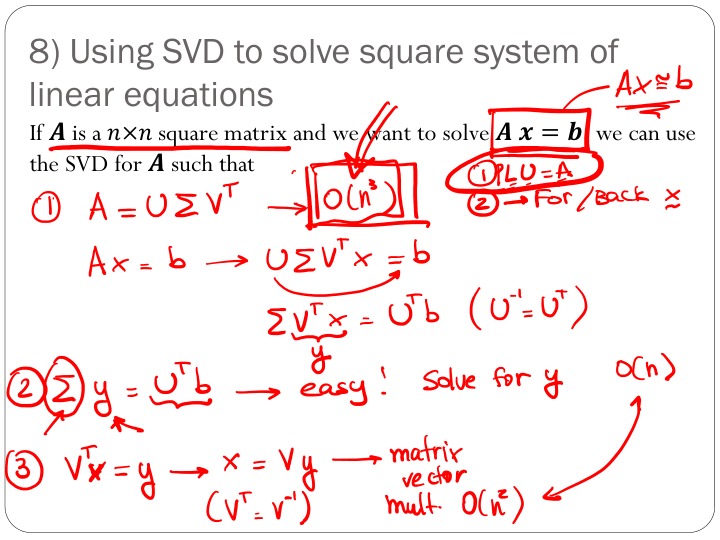

<details>
<summary>Example: Solve from factors without constructing A</summary>

Let $U=[e_3,(e_1+e_2)/\sqrt2,(e_1-e_2)/\sqrt2]$, $V=[e_2,e_3,e_1]$, and $\Sigma=\operatorname{diag}(8,3,1)$. Solve for $b=(\sqrt2,\sqrt2,1)^T$.

<details>
<summary>Solution</summary>

The inner products give $U^Tb=(1,2,0)^T$. Division gives $y=(1/8,2/3,0)^T$. Applying $V$ gives $x=(0,1/8,2/3)^T$.

</details>
</details>

In [5]:
a = 1 / np.sqrt(2)
Us = np.array([[0, a, a], [0, a, -a], [1, 0, 0]])
Vs = np.eye(3)[:, [1, 2, 0]]
ss = np.array([8., 3., 1.])
b = np.array([np.sqrt(2), np.sqrt(2), 1.])
sol = Vs @ ((Us.T @ b) / ss)
assert np.allclose(sol, [0, 1/8, 2/3])
assert np.allclose(((Us * ss) @ Vs.T) @ sol, b)
print('Solution:', sol)

Solution: [2.02930727e-17 1.25000000e-01 6.66666667e-01]


## 9. Formulas at a Glance

| Quantity | SVD expression |
| :--- | :--- |
| Exact rank | $\#\{i:\sigma_i>0\}$ |
| Pseudoinverse | $V_r\Sigma_r^{-1}U_r^T$ |
| Matrix 2-norm | $\sigma_1$ |
| Pseudoinverse 2-norm for $r>0$ | $1/\sigma_r$ |
| Full-rank condition number | $\sigma_1/\sigma_p$ |
| Optimal spectral residual for $k<r$ | $\sigma_{k+1}$ |
| Storage of truncated factors | $k(m+n+1)$ scalars |
| Nonsingular square solve | $V\Sigma^{-1}U^Tb$ |